#  Inspeção e Visualização de Modelos e Artefatos Guardados (`.pkl` e `.pt`)
**Unidade Curricular:** Aprendizagem Profunda — Trabalho Prático

Este notebook permite inspecionar de forma interativa, visual e detalhada todos os ficheiros guardados na pasta `models/` sem recurso a ferramentas externas (como Netron):

1.  `simple_tokenizer.pkl` — Vocabulário, comprimento de sequência e codificação de texto.
2.  `tfidf_vectorizer.pkl` — Matriz de termos, pesos IDF (Inverse Document Frequency) e vocabulário.
3.  `best_numpy_lr.pkl` — Regressão Logística NumPy (pesos por palavra $W$ e viés $b$).
4.  `best_numpy_dnn.pkl` — Rede Neuronal Profunda NumPy (camadas, ativações e parâmetros).
5.  **Modelos PyTorch (`.pt`):**
   - `best_pytorch_dnn.pt` — Rede Densa Tabular com TF-IDF, BatchNorm e Dropout.
   - `best_pytorch_bilstm.pt` — Rede Recorrente Bidirecional (BiLSTM) com Camada de Embeddings.
   - `best_pytorch_transformer.pt` — Transformer Encoder com Multi-Head Attention e Positional Encoding.

In [1]:
# 1. Configuração de Ambiente e Importações
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Configuração de estilo para os gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# Adicionar a pasta 'src' ao sys.path (suporta execução a partir da raiz ou da pasta notebooks/)
for path_candidate in ["../src", "src", "."]:
    abs_path = os.path.abspath(path_candidate)
    if os.path.exists(abs_path) and abs_path not in sys.path:
        sys.path.insert(0, abs_path)

from inference import robust_pickle_load

# Localização da pasta models
models_dir = "../models" if os.path.exists("../models") else "models"
print(f"[*] Pasta de modelos identificada: {os.path.abspath(models_dir)}")
print(f"[*] Ficheiros disponíveis: {sorted(os.listdir(models_dir))}")

[*] Pasta de modelos identificada: c:\Users\HP ZBOOK POWER G7\Documents\nosso_trabalho_ap\models
[*] Ficheiros disponíveis: ['best_numpy_dnn.pkl', 'best_numpy_lr.pkl', 'best_pytorch_bilstm.pt', 'best_pytorch_dnn.pt', 'best_pytorch_transformer.pt', 'simple_tokenizer.pkl', 'tfidf_vectorizer.pkl']


---
## 1.  Inspeção: `simple_tokenizer.pkl`
O `SimpleTokenizer` converte texto em bruto em sequências numéricas de tokens de comprimento fixo com padding/truncagem.

In [2]:
tok_path = os.path.join(models_dir, "simple_tokenizer.pkl")
tokenizer = robust_pickle_load(tok_path)

print(f"• Tipo de Objeto             : {type(tokenizer).__name__}")
print(f"• Tamanho Real do Vocabulário: {tokenizer.vocab_size} tokens únicos")
print(f"• Capacidade Máxima          : {tokenizer.max_vocab_size} tokens")
print(f"• Comprimento Fixo (Padding) : {tokenizer.max_seq_len} tokens")

# Amostra de tokens mapeados
df_vocab = pd.DataFrame(list(tokenizer.vocab.items())[:30], columns=["Token / Palavra", "ID Numérico"])
print("\nPrimeiros 30 tokens do vocabulário:")
display(df_vocab.head(15))

# Teste de codificação interativo
exemplo_texto = "The deep learning model analyzes natural language processing sequences."
encoded = tokenizer.encode(exemplo_texto)
print(f"\n[*] Exemplo de Codificação de Texto:")
print(f"  Texto : '{exemplo_texto}'")
print(f"  Tokens: {encoded[:15]}... (Total: {len(encoded)} posições)")

• Tipo de Objeto             : SimpleTokenizer
• Tamanho Real do Vocabulário: 3871 tokens únicos
• Capacidade Máxima          : 5000 tokens
• Comprimento Fixo (Padding) : 150 tokens

Primeiros 30 tokens do vocabulário:


,Token / Palavra,ID Numérico
0,<PAD>,0
1,<UNK>,1
2,the,2
3,of,3
4,and,4
5,in,5
6,to,6
7,a,7
8,is,8
9,for,9



[*] Exemplo de Codificação de Texto:
  Texto : 'The deep learning model analyzes natural language processing sequences.'
  Tokens: [2, 580, 199, 124, 1, 186, 1, 3270, 1, 0, 0, 0, 0, 0, 0]... (Total: 150 posições)


---
## 2.  Inspeção: `tfidf_vectorizer.pkl`
O `TfidfVectorizer` extrai as 1000 features léxicas mais relevantes ponderadas por TF-IDF.

• Tipo de Objeto             : TfidfVectorizer
• Total de Termos Extraídos  : 1000
• Intervalo de N-Gramas      : (1, 1)


C:\Users\HP ZBOOK POWER G7\AppData\Local\Temp\ipykernel_11404\2362134598.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_bottom, x="Peso_IDF", y="Termo", palette="viridis", ax=ax2)


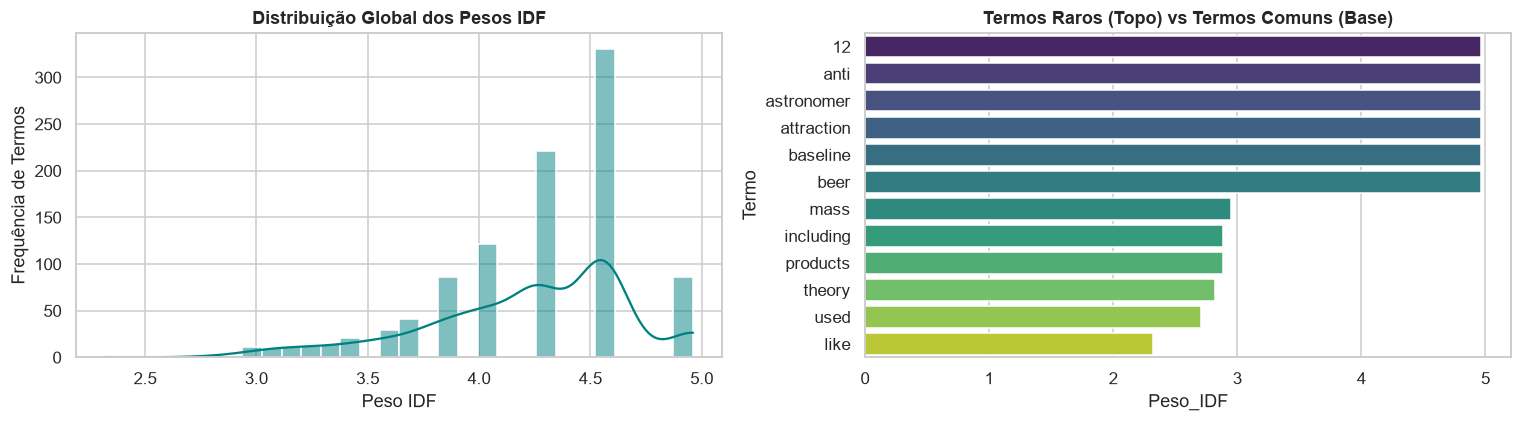

In [3]:
vec_path = os.path.join(models_dir, "tfidf_vectorizer.pkl")
vectorizer = robust_pickle_load(vec_path)
feature_names = vectorizer.get_feature_names_out()

print(f"• Tipo de Objeto             : {type(vectorizer).__name__}")
print(f"• Total de Termos Extraídos  : {len(feature_names)}")
print(f"• Intervalo de N-Gramas      : {getattr(vectorizer, 'ngram_range', '1-gram')}")

idf_data = sorted(zip(feature_names, vectorizer.idf_), key=lambda x: x[1], reverse=True)
df_idf = pd.DataFrame(idf_data, columns=["Termo", "Peso_IDF"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_idf["Peso_IDF"], bins=30, kde=True, color="teal", ax=ax1)
ax1.set_title("Distribuição Global dos Pesos IDF", fontweight="bold")
ax1.set_xlabel("Peso IDF")
ax1.set_ylabel("Frequência de Termos")

top_bottom = pd.concat([df_idf.head(6), df_idf.tail(6)])
sns.barplot(data=top_bottom, x="Peso_IDF", y="Termo", palette="viridis", ax=ax2)
ax2.set_title("Termos Raros (Topo) vs Termos Comuns (Base)", fontweight="bold")
plt.tight_layout()
plt.show()

---
## 3.  Inspeção: `best_numpy_lr.pkl` (Regressão Logística NumPy)
A Regressão Logística é uma camada linear com ativação Sigmoid. Os seus coeficientes indicam diretamente quais palavras pesam a favor de **IA** (pesos positivos) ou de **Humano** (pesos negativos).

• Dimensão dos Pesos W: (1000, 1) (1000 parâmetros)
• Valor do Bias b     : -0.3736
• Média dos Pesos     : 0.0410 | Desvio Padrão: 0.3609


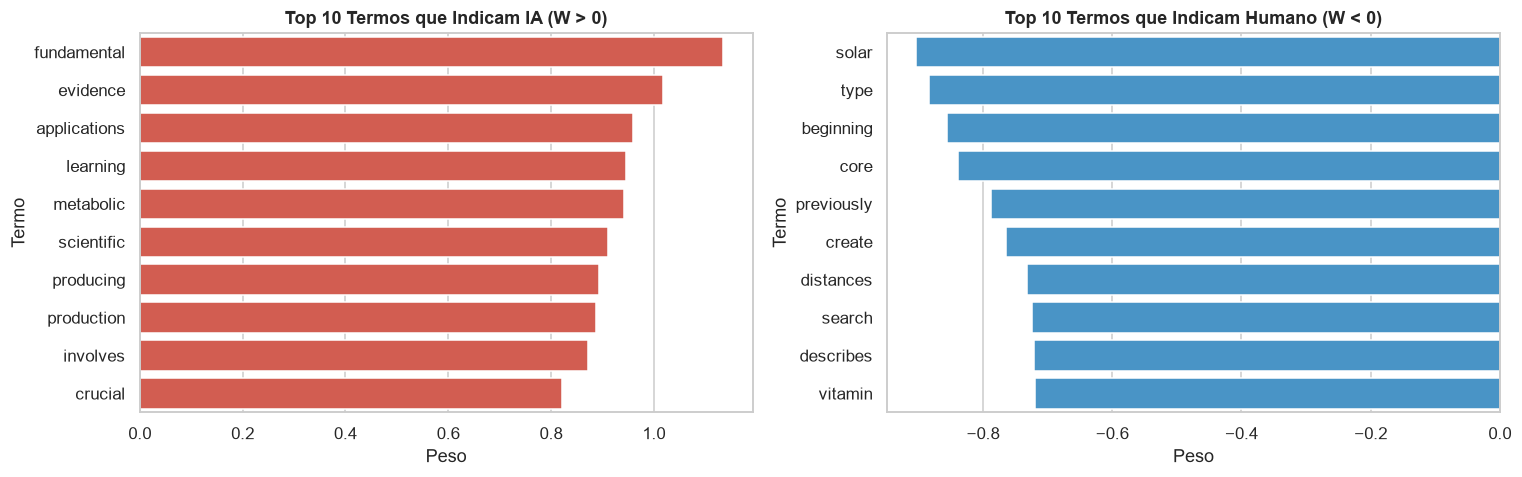

In [4]:
lr_path = os.path.join(models_dir, "best_numpy_lr.pkl")
lr_model = robust_pickle_load(lr_path)

dense_lr = lr_model.layers[0]
w_lr = dense_lr.weights.flatten()
b_lr = dense_lr.biases.flatten()[0] if hasattr(dense_lr.biases, '__iter__') else dense_lr.biases

print(f"• Dimensão dos Pesos W: {dense_lr.weights.shape} ({dense_lr.weights.size} parâmetros)")
print(f"• Valor do Bias b     : {b_lr:+.4f}")
print(f"• Média dos Pesos     : {np.mean(w_lr):.4f} | Desvio Padrão: {np.std(w_lr):.4f}")

# Termos mais associados a IA e a Humano
term_weights = pd.DataFrame({"Termo": feature_names, "Peso": w_lr})
top_ai = term_weights.sort_values(by="Peso", ascending=False).head(10)
top_human = term_weights.sort_values(by="Peso", ascending=True).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=top_ai, x="Peso", y="Termo", color="#e74c3c", ax=axes[0])
axes[0].set_title("Top 10 Termos que Indicam IA (W > 0)", fontweight="bold")

sns.barplot(data=top_human, x="Peso", y="Termo", color="#3498db", ax=axes[1])
axes[1].set_title("Top 10 Termos que Indicam Humano (W < 0)", fontweight="bold")
plt.tight_layout()
plt.show()

---
## 4.  Inspeção: `best_numpy_dnn.pkl` (Rede Neuronal Profunda NumPy)
A DNN construída de raiz em NumPy possui múltiplas camadas densas e funções de ativação (ReLU, Sigmoid).

In [5]:
dnn_path = os.path.join(models_dir, "best_numpy_dnn.pkl")
dnn_model = robust_pickle_load(dnn_path)

dnn_layers = []
total_dnn_params = 0

for i, layer in enumerate(dnn_model.layers):
    nome = type(layer).__name__
    if hasattr(layer, 'weights') and layer.weights is not None:
        w_shape = str(list(layer.weights.shape))
        b_shape = str(list(layer.biases.shape)) if hasattr(layer, 'biases') and layer.biases is not None else "N/A"
        params = layer.weights.size + (layer.biases.size if hasattr(layer, 'biases') and layer.biases is not None else 0)
        total_dnn_params += params
        tipo = "Camada Parametrizada (Dense)"
    else:
        w_shape, b_shape, params = "-", "-", 0
        tipo = "Ativação / Não Linearidade"
        
    dnn_layers.append({
        "#": i + 1,
        "Classe": nome,
        "Tipo": tipo,
        "Shape W": w_shape,
        "Shape b": b_shape,
        "Parâmetros": params
    })

df_dnn = pd.DataFrame(dnn_layers)
print(f"[*] Total de Parâmetros Treináveis na DNN NumPy: {total_dnn_params:,}")
display(df_dnn)

[*] Total de Parâmetros Treináveis na DNN NumPy: 64,129


,#,Classe,Tipo,Shape W,Shape b,Parâmetros
0,1,DenseLayer,Camada Parametrizada (Dense),"[1000, 64]","[1, 64]",64064
1,2,ReLUActivation,Ativação / Não Linearidade,-,-,0
2,3,DenseLayer,Camada Parametrizada (Dense),"[64, 1]","[1, 1]",65
3,4,SigmoidActivation,Ativação / Não Linearidade,-,-,0


---
## 5.  Visão Geral Comparativa de Todos os Modelos Guardados
Comparação do tamanho em disco (KB / MB) e número total de parâmetros de todas as arquiteturas (NumPy e PyTorch).

,Ficheiro,Modelo,Framework,Tamanho (KB),Tamanho (MB),Nº Tensores,Total Parâmetros
0,best_numpy_lr.pkl,NumPy Logistic Regression,PKL / NumPy,118.24,0.12,2,1001
1,best_numpy_dnn.pkl,NumPy Deep Neural Network,PKL / NumPy,1117.93,1.09,4,64129
2,best_pytorch_dnn.pt,PyTorch Tabular DNN (TF-IDF),PT / PyTorch,541.93,0.53,16,137219
3,best_pytorch_bilstm.pt,PyTorch BiLSTM (Embeddings),PT / PyTorch,2751.35,2.69,21,702465
4,best_pytorch_transformer.pt,PyTorch Transformer Encoder,PT / PyTorch,5514.86,5.39,30,1408769


C:\Users\HP ZBOOK POWER G7\AppData\Local\Temp\ipykernel_11404\3679152331.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_overview, x="Tamanho (MB)", y="Modelo", palette="Blues_r", ax=ax1)
C:\Users\HP ZBOOK POWER G7\AppData\Local\Temp\ipykernel_11404\3679152331.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_overview, x="Total Parâmetros", y="Modelo", palette="Reds_r", ax=ax2)


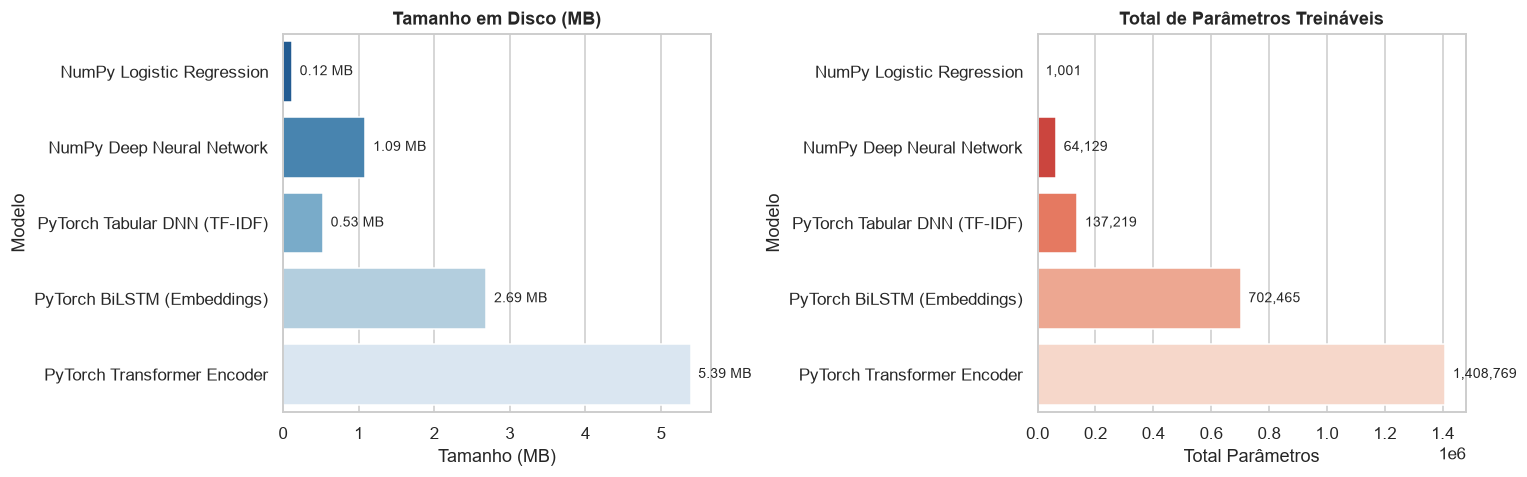

In [6]:
all_models = [
    ("best_numpy_lr.pkl", "NumPy Logistic Regression", "PKL / NumPy"),
    ("best_numpy_dnn.pkl", "NumPy Deep Neural Network", "PKL / NumPy"),
    ("best_pytorch_dnn.pt", "PyTorch Tabular DNN (TF-IDF)", "PT / PyTorch"),
    ("best_pytorch_bilstm.pt", "PyTorch BiLSTM (Embeddings)", "PT / PyTorch"),
    ("best_pytorch_transformer.pt", "PyTorch Transformer Encoder", "PT / PyTorch")
]

overview_rows = []
for fname, label, tech in all_models:
    fpath = os.path.join(models_dir, fname)
    if not os.path.exists(fpath):
        continue
    size_kb = os.path.getsize(fpath) / 1024
    
    if fname.endswith(".pt"):
        st = torch.load(fpath, map_location="cpu", weights_only=True)
        n_params = sum(t.numel() for t in st.values())
        n_tensors = len(st)
    elif fname == "best_numpy_lr.pkl":
        n_params = lr_model.layers[0].weights.size + lr_model.layers[0].biases.size
        n_tensors = 2
    elif fname == "best_numpy_dnn.pkl":
        n_params = total_dnn_params
        n_tensors = sum(1 for l in dnn_model.layers if hasattr(l, 'weights') and l.weights is not None) * 2
    else:
        n_params, n_tensors = 0, 0
        
    overview_rows.append({
        "Ficheiro": fname,
        "Modelo": label,
        "Framework": tech,
        "Tamanho (KB)": round(size_kb, 2),
        "Tamanho (MB)": round(size_kb / 1024, 2),
        "Nº Tensores": n_tensors,
        "Total Parâmetros": n_params
    })

df_overview = pd.DataFrame(overview_rows)
display(df_overview)

# Gráficos comparativos de tamanho e parâmetros
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=df_overview, x="Tamanho (MB)", y="Modelo", palette="Blues_r", ax=ax1)
ax1.set_title("Tamanho em Disco (MB)", fontweight="bold")
for p in ax1.patches:
    width = p.get_width()
    ax1.annotate(f"{width:.2f} MB", (width, p.get_y() + p.get_height() / 2.),
                 ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=9)

sns.barplot(data=df_overview, x="Total Parâmetros", y="Modelo", palette="Reds_r", ax=ax2)
ax2.set_title("Total de Parâmetros Treináveis", fontweight="bold")
for p in ax2.patches:
    width = p.get_width()
    ax2.annotate(f"{int(width):,}", (width, p.get_y() + p.get_height() / 2.),
                 ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()

---
## 5.1  Inspeção Detalhada: `best_pytorch_dnn.pt`
Rede tabular densa em PyTorch treinada sobre os vetores TF-IDF (1000 dimensões), incorporando `Linear`, `BatchNorm1d` e ativação `ReLU`.

[*] PyTorch DNN — Total de Parâmetros: 137,219


,Tensor / Camada,Dimensões (Shape),Parâmetros,Dtype,Média,Desvio Padrão
0,network.0.weight,"[128, 1000]",128000,float32,0.000071,0.018461
1,network.0.bias,[128],128,float32,0.001211,0.020258
2,network.1.weight,[128],128,float32,0.999982,0.003118
3,network.1.bias,[128],128,float32,-0.000032,0.002983
4,network.1.running_mean,[128],128,float32,0.000770,0.011004
5,network.1.running_var,[128],128,float32,0.478474,0.000031
6,network.1.num_batches_tracked,[],1,int64,7.000000,0.000000
7,network.4.weight,"[64, 128]",8192,float32,-0.000397,0.050804
8,network.4.bias,[64],64,float32,-0.004094,0.054075
9,network.5.weight,[64],64,float32,0.998944,0.003487


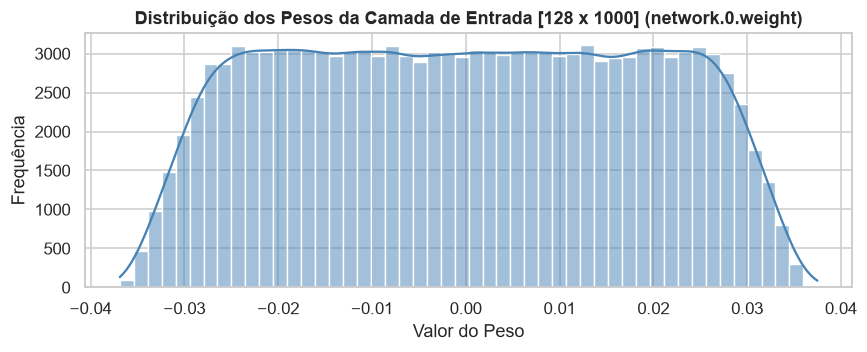

In [7]:
path_pt_dnn = os.path.join(models_dir, "best_pytorch_dnn.pt")
state_pt_dnn = torch.load(path_pt_dnn, map_location="cpu", weights_only=True)

rows_dnn = []
for k, v in state_pt_dnn.items():
    rows_dnn.append({
        "Tensor / Camada": k,
        "Dimensões (Shape)": str(list(v.shape)),
        "Parâmetros": v.numel(),
        "Dtype": str(v.dtype).replace("torch.", ""),
        "Média": float(v.float().mean()),
        "Desvio Padrão": float(v.float().std()) if v.numel() > 1 else 0.0
    })

df_pt_dnn = pd.DataFrame(rows_dnn)
print(f"[*] PyTorch DNN — Total de Parâmetros: {df_pt_dnn['Parâmetros'].sum():,}")
display(df_pt_dnn)

# Histograma dos pesos da primeira camada (network.0.weight)
w0 = state_pt_dnn["network.0.weight"].cpu().numpy().flatten()
plt.figure(figsize=(9, 3))
sns.histplot(w0, bins=50, kde=True, color="steelblue")
plt.title("Distribuição dos Pesos da Camada de Entrada [128 x 1000] (network.0.weight)", fontweight="bold")
plt.xlabel("Valor do Peso")
plt.ylabel("Frequência")
plt.show()

---
## 5.2  Inspeção Detalhada: `best_pytorch_bilstm.pt`
Rede Recorrente Bidirecional (BiLSTM) de 2 camadas com camada de Embeddings (3871 palavras $\times$ 128 dimensões) e cabeça classificadora totalmente ligada (`fc`).

[*] PyTorch BiLSTM — Total de Parâmetros: 702,465


,Tensor / Camada,Dimensões (Shape),Parâmetros,Dtype,Média,Desvio Padrão
0,embedding.weight,"[3871, 128]",495488,float32,-0.001363,0.999361
1,lstm.weight_ih_l0,"[256, 128]",32768,float32,0.000109,0.075690
2,lstm.weight_hh_l0,"[256, 64]",16384,float32,0.000724,0.077043
3,lstm.bias_ih_l0,[256],256,float32,0.011031,0.077344
4,lstm.bias_hh_l0,[256],256,float32,0.012636,0.079030
5,lstm.weight_ih_l0_reverse,"[256, 128]",32768,float32,-0.000390,0.075501
6,lstm.weight_hh_l0_reverse,"[256, 64]",16384,float32,0.002138,0.077290
7,lstm.bias_ih_l0_reverse,[256],256,float32,0.009460,0.076639
8,lstm.bias_hh_l0_reverse,[256],256,float32,0.011384,0.080398
9,lstm.weight_ih_l1,"[256, 128]",32768,float32,0.001092,0.077267


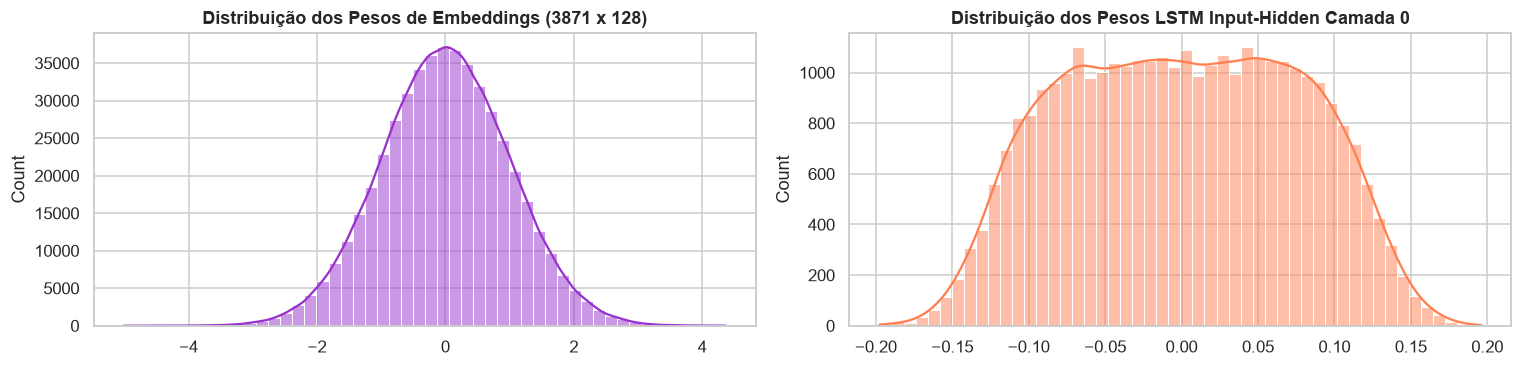

In [8]:
path_pt_lstm = os.path.join(models_dir, "best_pytorch_bilstm.pt")
state_pt_lstm = torch.load(path_pt_lstm, map_location="cpu", weights_only=True)

rows_lstm = []
for k, v in state_pt_lstm.items():
    rows_lstm.append({
        "Tensor / Camada": k,
        "Dimensões (Shape)": str(list(v.shape)),
        "Parâmetros": v.numel(),
        "Dtype": str(v.dtype).replace("torch.", ""),
        "Média": float(v.float().mean()),
        "Desvio Padrão": float(v.float().std()) if v.numel() > 1 else 0.0
    })

df_pt_lstm = pd.DataFrame(rows_lstm)
print(f"[*] PyTorch BiLSTM — Total de Parâmetros: {df_pt_lstm['Parâmetros'].sum():,}")
display(df_pt_lstm)

# Distribuição dos pesos dos Embeddings vs Pesos das Portas LSTM
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 3.5))
w_emb = state_pt_lstm["embedding.weight"].cpu().numpy().flatten()
sns.histplot(w_emb, bins=50, kde=True, color="darkorchid", ax=ax1)
ax1.set_title("Distribuição dos Pesos de Embeddings (3871 x 128)", fontweight="bold")

w_lstm = state_pt_lstm["lstm.weight_ih_l0"].cpu().numpy().flatten()
sns.histplot(w_lstm, bins=50, kde=True, color="coral", ax=ax2)
ax2.set_title("Distribuição dos Pesos LSTM Input-Hidden Camada 0", fontweight="bold")
plt.tight_layout()
plt.show()

---
## 5.3  Inspeção Detalhada: `best_pytorch_transformer.pt`
Transformer Encoder com Camada de Embeddings, Codificação Posicional Sinusoidal (`pos_encoder.pe`), camadas de Self-Attention Multi-Head (`self_attn`), Feed-Forward Networks e Classificador Final.

[*] PyTorch Transformer — Total de Parâmetros: 1,408,769


,Tensor / Camada,Dimensões (Shape),Parâmetros,Dtype,Média,Desvio Padrão
0,embedding.weight,"[3871, 128]",495488,float32,0.001662,0.999823
1,pos_encoder.pe,"[1, 5000, 128]",640000,float32,0.128391,0.695353
2,transformer_encoder.layers.0.self_attn.in_proj...,"[384, 128]",49152,float32,0.000284,0.062761
3,transformer_encoder.layers.0.self_attn.in_proj...,[384],384,float32,-0.000056,0.002122
4,transformer_encoder.layers.0.self_attn.out_pro...,"[128, 128]",16384,float32,0.000208,0.051065
5,transformer_encoder.layers.0.self_attn.out_pro...,[128],128,float32,0.000034,0.001783
6,transformer_encoder.layers.0.linear1.weight,"[256, 128]",32768,float32,-0.000297,0.050810
7,transformer_encoder.layers.0.linear1.bias,[256],256,float32,0.001014,0.048977
8,transformer_encoder.layers.0.linear2.weight,"[128, 256]",32768,float32,-0.000050,0.036014
9,transformer_encoder.layers.0.linear2.bias,[128],128,float32,-0.003904,0.035700


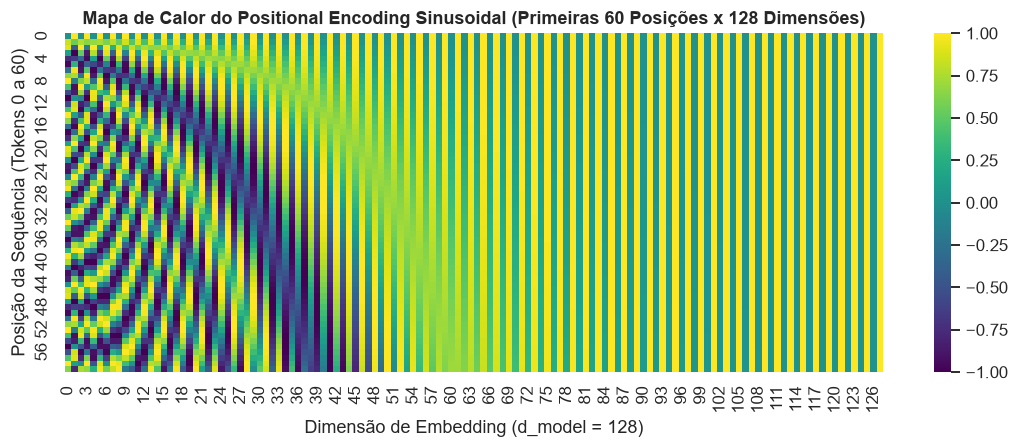

In [9]:
path_pt_trans = os.path.join(models_dir, "best_pytorch_transformer.pt")
state_pt_trans = torch.load(path_pt_trans, map_location="cpu", weights_only=True)

rows_trans = []
for k, v in state_pt_trans.items():
    rows_trans.append({
        "Tensor / Camada": k,
        "Dimensões (Shape)": str(list(v.shape)),
        "Parâmetros": v.numel(),
        "Dtype": str(v.dtype).replace("torch.", ""),
        "Média": float(v.float().mean()),
        "Desvio Padrão": float(v.float().std()) if v.numel() > 1 else 0.0
    })

df_pt_trans = pd.DataFrame(rows_trans)
print(f"[*] PyTorch Transformer — Total de Parâmetros: {df_pt_trans['Parâmetros'].sum():,}")
display(df_pt_trans)

# Visualização da Matriz de Codificação Posicional (Positional Encoding)
pe_tensor = state_pt_trans["pos_encoder.pe"].squeeze(0).cpu().numpy()

plt.figure(figsize=(12, 4))
sns.heatmap(pe_tensor[:60, :], cmap="viridis", cbar=True)
plt.title("Mapa de Calor do Positional Encoding Sinusoidal (Primeiras 60 Posições x 128 Dimensões)", fontweight="bold")
plt.xlabel("Dimensão de Embedding (d_model = 128)")
plt.ylabel("Posição da Sequência (Tokens 0 a 60)")
plt.show()

---
## 6.  Resumo Final e Conclusão
Todos os ficheiros serializados (`.pkl` e `.pt`) foram carregados e validados com sucesso no notebook.

| Ficheiro | Tipo / Arquitetura | Parâmetros | Utilidade no Pipeline |
| :--- | :--- | :--- | :--- |
| `simple_tokenizer.pkl` | Tokenizador de Texto | Vocab: 3871 | Pré-processamento de sequências (BiLSTM & Transformer) |
| `tfidf_vectorizer.pkl` | Vetorizador TF-IDF | 1000 features | Pré-processamento tabular (LR, NumPy DNN, PyTorch DNN) |
| `best_numpy_lr.pkl` | Regressão Logística | 1,001 | Baseline linear interpretável |
| `best_numpy_dnn.pkl` | Deep Neural Network | 64,129 | Modelo de rede densa implementado do zero em NumPy |
| `best_pytorch_dnn.pt` | PyTorch Tabular DNN | 137,219 | Modelo tabular moderno com BatchNorm e Dropout |
| `best_pytorch_bilstm.pt` | PyTorch BiLSTM | 702,465 | Modelo sequencial recorrente bidirecional com embeddings |
| `best_pytorch_transformer.pt` | PyTorch Transformer | 1,408,769 | Modelo de atenção com Transformer Encoder |
